**OBJECTIVE OF THE FILE**

- Here we are experimenting and analysing how the data should be 
- Data visualization to see what king of data you are going to deal with
- Data integration 
- Data Preprocessing
   - data loading
   - data resizing
   - data augmentation
   - data normalization
- Model building and training
- Model Pusher

In [ ]:
##  IMPORTS #

import os
import numpy as np

from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
%matplotlib inline


import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets, models
from torch.optim.lr_scheduler import StepLR
from torchsummary import summary


from tqdm import tqdm


`DATA VISUALIZATION BEFORE GOING FORWARD`

- Need to know the features of dataset 
- How is data divided , the format
- how are images looking

In [27]:
# visualization using matplot #

data_path = r"../Data"

In [28]:
# creating list of classes #

class_name = ["NORMAL", "PNEUMONIA" ]
def get_list_files(dir_name):

    file_list = os.listdir(dir_name)
    return file_list

file_list_train_normal = get_list_files(data_path+'/train/'+class_name[0])
file_list_train_pneumonia = get_list_files(data_path+'/train/'+class_name[1])
file_list_test_normal = get_list_files(data_path+'/test/'+class_name[0])
file_list_test_pneumonia = get_list_files(data_path+'/test/'+class_name[1])

#printing file list
print("total files in train normal:", len(file_list_train_normal))
print("total files in train pneumonia:", len(file_list_train_pneumonia))
print("total files in test normal:", len(file_list_test_normal))
print("total files in test pneumonia:", len(file_list_test_pneumonia))

total files in train normal: 1266
total files in train pneumonia: 3418
total files in test normal: 317
total files in test pneumonia: 855


(1221, 1467, 3)


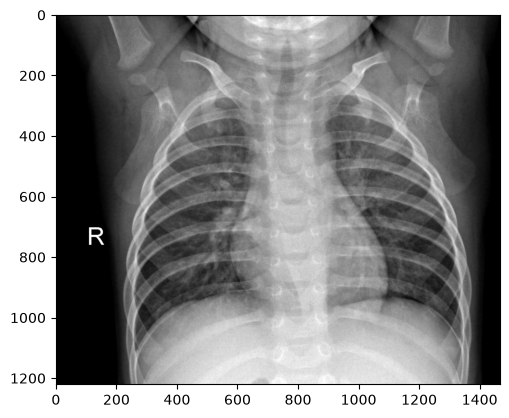

In [29]:
# now we can visualize the normal data

#choosing a random image
img = data_path + '/train/NORMAL/' + file_list_train_normal[np.random.randint(0, len(file_list_train_normal))]

image = mpimg.imread(img)
print(image.shape)
plt.imshow(image)
plt.show()

(800, 1112, 3)


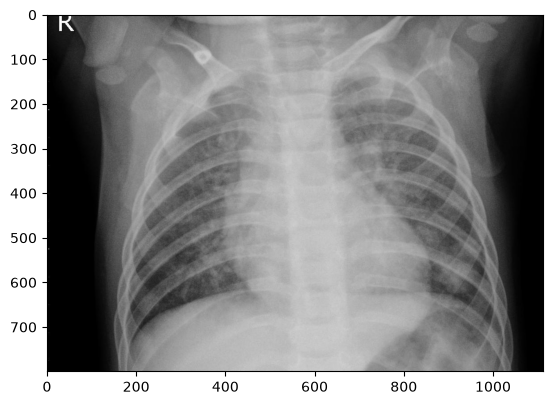

In [30]:
# now we can visualize the pneumonia data

#choosing a random image
img = data_path + '/train/PNEUMONIA/' + file_list_train_pneumonia[np.random.randint(0, len(file_list_train_pneumonia))]

image = mpimg.imread(img)
print(image.shape)
plt.imshow(image)
plt.show()

**ANALYSIS TILL NOW**

From above we can conclude that that image sizes are different and we need to provide a specific image for cnn, so we need to transform data that is resizing, normalizing




**DATA PREPROCESSING**

In [31]:
# # first we will need mean and std deviation for normalization process 

# pixels = []

# # pixel_sum = np.zeros(3)
# # pixel_sum_squared = np.zeros(3)
# # pixel_count = 0

# for i in class_name:
#     img_target_folder = os.path.join(data_path + '/train/', i)


#     for img_file in os.listdir(img_target_folder):
#         img = Image.open(os.path.join(img_target_folder, img_file)).convert("RGB")
#         img = img.resize((224, 224))
#         img = np.asarray(img, dtype=np.float32)/255.0

#         pixels.append(img)

# pixels = np.concatenate([x.reshape(-1, 3) for x in pixels])

#         # img = img.reshape(-1, 3)

#         # pixel_sum += np.sum(img, axis=0)
#         # pixel_sum_squared += np.sum(img ** 2, axis=0)
#         # pixel_count += img.shape[0]


# mean = np.mean(pixels, axis=0)
# std = np.std(pixels, axis=0)
# # mean = pixel_sum / pixel_count

# # std = np.sqrt(
# #     (pixel_sum_squared / pixel_count) - (mean ** 2))

# print("mean is", mean)
# print("std is", std)




In [32]:
# creating two transformers for train and test data

train_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(saturation=0.01, hue=0.1, contrast=0.1, brightness=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.489251, 0.489251, 0.489251], [0.23298936, 0.23298936, 0.23298936])
])

test_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.489251, 0.489251, 0.489251], [0.23298936, 0.23298936, 0.23298936])
])

---
---
# **MODEL ARCHITECTURE BEGINS HERE**

**DATA LOADING USING DATALOADER**

HERE AFTER DATA LOADING WE WILL USE PREPROCESSING DONE USING TRAIN AND TEST_TRANSFORM
1. we will select data folder and will preform transform operation for both data_set 

In [33]:
##DATA LOADING

train_data = datasets.ImageFolder(os.path.join(data_path, 'train'), transform=train_transform)
test_data = datasets.ImageFolder(os.path.join(data_path, 'test'), transform=test_transform)
# after successful transforming dataset noe need to loading

train_loader = DataLoader(train_data, shuffle=True, 
                          batch_size=2,    # give 2 images at a time during testing
                          pin_memory=True) # for using gpu

test_loader = DataLoader(test_data, shuffle=True, 
                          batch_size=2,    # give 2 images at a time during testing
                          pin_memory=True) # for using gpu

print("total train images:", len(train_data))
print("total test images:", len(test_data))

total train images: 4684
total test images: 1172


In [34]:
# SINCE WE WILL TRAIN A NETWORK FOR FASTER DEPLOYMENT NEED GPU 
# So, we will use cuda to preform it

device = "cuda" if torch.cuda.is_available() else "cpu"
print("using :=>", {device}, "device")

using :=> {'cpu'} device


**ARCHITECTURE**

- WE will be using a conv architecture with total of 9 layers
- We will use pooling for first three layers for better feature extraction
- Will be using filter of 3*3
- Padding 0 , and bias=true
- Relu() function for deep layers & softmax for output since having 2 classes

In [35]:
class NeuralNetwork(nn.Module):   # NeuralNetwork class i.e (created by me) is inheriting from PyTorch's nn.Module(i.e base class for nn) class
    def __init__(self):           # constructor of your NeuralNetwork , runs auto when created

        super().__init__()    # job is to initialize the parent class (nn.Module).
        # So when you create your neural network, you need to initialize the nn.Module part too.
        # super(...) essentially says: "Run the initialization of my parent class."


 ## INPUT BLOCK 


        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_channels=3,       # since RGB
                    out_channels=8,        # Create 8 different filters that will learn 8 different types of features, gets deeper,
                                           # you can afford more feature channels because the spatial dimensions are becoming smaller using (pooling).
                    kernel_size=(3, 3), 
                    padding=0, 
                    bias=True),

            nn.ReLU(),
            nn.BatchNorm2d(8)       # performs batch normalization on the 8 feature channels produced by your convolution
        )
        self.poolingL1 = nn.MaxPool2d(2, 2)


 ## 1ST CONVOLUTION BLOCK         

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(8, 20, 3, padding=0, bias=True),

            nn.ReLU(),
            nn.BatchNorm2d(20)
        )
        self.poolingL2 = nn.MaxPool2d(2, 2)


 ## 1ST CONVOLUTION BLOCK

        self.conv_block3 = nn.Sequential(
                    nn.Conv2d(20, 8, 3, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(8)
        )
        self.poolingL3 = nn.MaxPool2d(2, 2)


 # 3rd CONVOLUTION BLOCK

        self.conv_block4 = nn.Sequential(
                    nn.Conv2d(8, 20, 1, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(20)
        )
        

 # 4th CONVOLUTION BLOCK

        self.conv_block5 = nn.Sequential(
                    nn.Conv2d(20, 36, 3, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(36)
        )
                
 # 5th CONVOLUTION BLOCK

        self.conv_block6 = nn.Sequential(
                    nn.Conv2d(36, 20, 3, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(20)
        )
                

 # 6th CONVOLUTION BLOCK

        self.conv_block7 = nn.Sequential(
                    nn.Conv2d(20, 36, 1, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(36)
        )
                
 # 7ST CONVOLUTION BLOCK

        self.conv_block8 = nn.Sequential(
                    nn.Conv2d(36, 8, 3, padding=0, bias=True),
        
                    nn.ReLU(),
                    nn.BatchNorm2d(8)
        )

 # FULLY CONNECTED LAYERS
        # till here the format is => [batch, 8, H, W] but we need but, since we need 8 values not [format] for fcn
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) # we use globalpooling => [batch, 8, 1, 1]
        #Each of the 8 channels has been reduced to one number — the average of all its H × W values.

        self.fc = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.poolingL1(x)

        x = self.conv_block2(x)
        x = self.poolingL2(x)

        x = self.conv_block3(x)
        x = self.poolingL3(x)

        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.conv_block6(x)
        x = self.conv_block7(x)
        x = self.conv_block8(x)

        x = self.gap(x)            # image = [batch, 8, 1, 1]
        x = torch.flatten(x, 1)    # image = [batch, 8]

        x = self.fc(x)

        return x

        
        

In [36]:
model = NeuralNetwork().to(device)
summary(model, input_size=(3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
       BatchNorm2d-3          [-1, 8, 222, 222]              16
         MaxPool2d-4          [-1, 8, 111, 111]               0
            Conv2d-5         [-1, 20, 109, 109]           1,460
              ReLU-6         [-1, 20, 109, 109]               0
       BatchNorm2d-7         [-1, 20, 109, 109]              40
         MaxPool2d-8           [-1, 20, 54, 54]               0
            Conv2d-9            [-1, 8, 52, 52]           1,448
             ReLU-10            [-1, 8, 52, 52]               0
      BatchNorm2d-11            [-1, 8, 52, 52]              16
        MaxPool2d-12            [-1, 8, 26, 26]               0
           Conv2d-13           [-1, 20, 26, 26]             180
             ReLU-14           [-1, 20,

---
---

# TRAINING & TESTING OF DATASET

In [ ]:
# defining loss function
loss_fn = nn.CrossEntropyLoss()

# defining optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
scheduler = StepLR(optimizer, step_size=6, gamma=0.5)

"""| Code                 | Purpose                          |
| -------------------- | -------------------------------- |
| `CrossEntropyLoss()` | Calculates **loss**              |
| `lr=0.01`            | Initial learning rate            |
| `optimizer`          | Updates model weights            |
| `step_size`          | When to reduce learning rate     |
| `gamma`              | How much to reduce learning rate |
"""

In [43]:
train_acc = []
test_acc = []
train_losses = []
test_losses = []


def train(model, train_loader, loss_fn, optimizer, device):
    model.train()

    progress_bar = tqdm(train_loader)
    correctly_pred = 0
    processed = 0

    for batch_indx, (data, label) in enumerate(progress_bar):  # here data is X, & label is Y i.e(target)

          
          # batch_idx = 0
          #data  = first batch of images
          #target  = labels for those images
        
        data, label = data.to(device), label.to(device)     # moving data and labels to cpu/gpu



      # Zero your gradients for every batch!
        optimizer.zero_grad()

      # Make predictions for this batch
        y_pred = model(data)

      # Calculate loss 
        loss = loss_fn(y_pred, label)  
        train_losses.append(loss)

      # bakpropogation and updation of weights
        loss.backward()
        optimizer.step()   # weight updatation



      #  # Gather data and report
      # get the index of the log-probability corresponding to the max value
      # GETTING PREDICTION
       
        pred = y_pred.argmax(dim=1, keepdim=True)
        correctly_pred += pred.eq(                 # see if pridction and target are equal
            label.view_as(pred)                    # view_as(pred) changes target to the same shape as pred for better comparision
        ).sum().item()                             # pytorch gives no. in tensor, .item() coverts it to simple python number


        processed += len(data)


        # gather data and report
        # what description you want during progress of your training output
        progress_bar.set_description(desc=f'loss = {loss.item()} Batchid = {batch_indx}, Accuracy = {100*correctly_pred/processed:0.2f}')
        train_acc.append(100*correctly_pred/processed)



def test(model, device, test_loader, loss_fn):
    model.eval()
    test_loss = 0
    correct_pred = 0

    with torch.no_grad():
        for data, label in test_loader:
            data, label = data.to(device), label.to(device)

            output = model(data)

            loss = loss_fn(output, label)
            test_loss += loss.item()                         # adding loss to test_loss

            pred = output.argmax(dim=1, keepdim=True)
            correct_pred += pred.eq(label.view_as(pred)).sum().item()


    test_loss /= len(test_loader.dataset) # basically it is dividing all the accumulated loss by the length of test_loader => gives average loss per batch
    test_losses.append(test_loss)

    print(f"Test error: \n Accuracy: {100.*correct_pred / len(test_loader.dataset)} %,  Avg loss: {test_loss:0.2f}\n")

    test_acc.append(100. * correct_pred / len(test_loader.dataset))


    

  0%|          | 0/2342 [03:01<?, ?it/s]


In [44]:
# training for 5 epochs

epochs = 5

for i in range(epochs):
    print(f"EPOCH, {i+1} \n ---------------------------------")
    train(model, train_loader, loss_fn, optimizer, device)
    test(model, device, test_loader, loss_fn)

print("done")    

EPOCH, 1 
 ---------------------------------


  0%|          | 0/2342 [00:00<?, ?it/s]c:\Users\vikra\Desktop\deep_learn\Deep\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
loss = 0.22992955148220062 Batchid = 2341, Accuracy = 78.74: 100%|██████████| 2342/2342 [02:14<00:00, 17.45it/s]


Test error: 
 Accuracy: 90.52901023890784 %,  Avg loss: 0.13

EPOCH, 2 
 ---------------------------------


loss = 0.1555519998073578 Batchid = 2341, Accuracy = 84.03: 100%|██████████| 2342/2342 [02:21<00:00, 16.59it/s]  


Test error: 
 Accuracy: 90.78498293515358 %,  Avg loss: 0.12

EPOCH, 3 
 ---------------------------------


...

Test error: 
 Accuracy: 86.3481228668942 %,  Avg loss: 0.26

EPOCH, 4 
 ---------------------------------


loss = 0.9738420248031616 Batchid = 2341, Accuracy = 86.64: 100%|██████████| 2342/2342 [02:17<00:00, 16.99it/s]   


Test error: 
 Accuracy: 90.95563139931741 %,  Avg loss: 0.14

EPOCH, 5 
 ---------------------------------


loss = 0.2697784900665283 Batchid = 2341, Accuracy = 88.07: 100%|██████████| 2342/2342 [02:16<00:00, 17.18it/s]   


Test error: 
 Accuracy: 89.07849829351535 %,  Avg loss: 0.21

done


torch.Size([3, 224, 224])
['NORMAL', 'PNEUMONIA']
predicted class is: 1


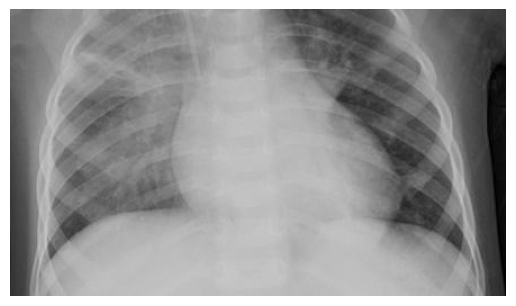

In [77]:
img = data_path + '/train/PNEUMONIA/' + file_list_train_pneumonia[np.random.randint(0, len(file_list_train_normal))]

# Open your single image
img = Image.open(img).convert("RGB")

# Apply the same train_transform
image_tensor = train_transform(img)

print(image_tensor.shape)

image_tensor = image_tensor.unsqueeze(0)

model.eval()

with torch.no_grad():
    image_tensor = image_tensor.to(device)

    output = model(image_tensor)

    predict = output.argmax(dim=1).item()

print(train_data.classes)
print("predicted class is:", predict)

plt.imshow(img)
plt.axis("off")
plt.show()




---
---
# SAVING THE MODEL

In [78]:
torch.save(model.state_dict(), "Xray_prediction_model.pth")